# 2. Model 1: points per possible game

Points per game rewards a scorer for the games he plays and says nothing about the games he misses. This notebook ranks every player both ways and shows who rises and who falls once missed games count.

Whole league, no minimum games (every player is included). Complete seasons 2020-21 to 2025-26; 2026-27 is shown separately at the end because it is still being played.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from adjustText import adjust_text
import pandas as pd

from xppg import data, plotting
from xppg.raw import PROJECT_ROOT
from xppg.show import table

plotting.use_style()
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_seasons.parquet")
ps["ppg_rank"] = ps.groupby("season").ppg.rank(ascending=False, method="min")
ps["pppg_rank"] = ps.groupby("season").pppg.rank(ascending=False, method="min")
ps["ppm_rank"] = ps.groupby("season").ppm.rank(ascending=False, method="min")
ps["pppm_rank"] = ps.groupby("season").pppm.rank(ascending=False, method="min")
assert (ps.pppm_rank == ps.pppg_rank).all()  # 48 possible minutes per possible game: same order as PPPG

def note(r):
    return ", ".join(n for n, f in [("Two-way contract", r.two_way), ("10-day contract", r.ten_day),
                                    ("Some dates unknown", r.undated)] if f)
ps["Note"] = ps.apply(note, axis=1)
done = ps[ps.season.isin(data.COMPLETE_SEASONS)]
LATEST = data.COMPLETE_SEASONS[-1]

## 1. Four ways to measure scoring

**What you're looking at:** the four measures used in this notebook.  
**Why it matters:** the first two are per game, the last two per minute. In each pair, the second one also counts the games a player missed.

In [2]:
measures = pd.DataFrame({
    "What it means": ["Points per game he played",
                      "Points per game his team played while he was on the roster",
                      "Points per minute he played",
                      "Points per minute he could have played (48 a game, every possible game)"],
    "Counts missed games?": ["No", "Yes", "No", "Yes"],
}, index=["PPG", "PPPG (points per possible game)", "PPM (points per minute)", "PPPM (points per possible minute)"])
table(measures.rename_axis("Measure"), "The four measures")

,What it means,Counts missed games?
Measure,,
PPG,Points per game he played,No
PPPG (points per possible game),Points per game his team played while he was on the roster,Yes
PPM (points per minute),Points per minute he played,No
PPPM (points per possible minute),"Points per minute he could have played (48 a game, every possible game)",Yes


## 2. The scoring leader, two ways

**What you're looking at:** each season's top scorer by points per game, next to the top scorer by points per possible game.  
**Why it matters:** when the two differ, the points-per-game leader missed enough games that someone more available gave his team more.

In [3]:
a = done.loc[done.groupby("season").ppg.idxmax()].set_index("season")
b = done.loc[done.groupby("season").pppg.idxmax()].set_index("season")
leaders = pd.DataFrame({
    "PPG leader": a.player_name, "PPG": a.ppg, "Played": a.gp.astype(str) + " of " + a.possible_games.astype(str),
    "PPPG leader": b.player_name, "PPPG": b.pppg, "Played ": b.gp.astype(str) + " of " + b.possible_games.astype(str),
})
table(leaders.rename_axis("Season"), "Scoring leaders: points per game against points per possible game")

,PPG leader,PPG,Played,PPPG leader,PPPG,Played
Season,,,,,,
2020-21,Stephen Curry,32.0,63 of 72,Stephen Curry,28.0,63 of 72
2021-22,Joel Embiid,30.6,68 of 82,Trae Young,26.3,76 of 82
2022-23,Joel Embiid,33.1,66 of 82,Jayson Tatum,27.1,74 of 82
2023-24,Joel Embiid,34.7,39 of 82,Luka Dončić,28.9,70 of 82
2024-25,Shai Gilgeous-Alexander,32.7,76 of 82,Shai Gilgeous-Alexander,30.3,76 of 82
2025-26,Luka Dončić,33.5,64 of 82,Luka Dončić,26.1,64 of 82


## 3. The top 15 scorers, re-ranked

**What you're looking at:** the 15 highest scorers by points per game in the latest complete season, and where each one ranks by points per possible game.  
**Why it matters:** the players who fall furthest are the ones who missed the most games. Their points per game hid it.

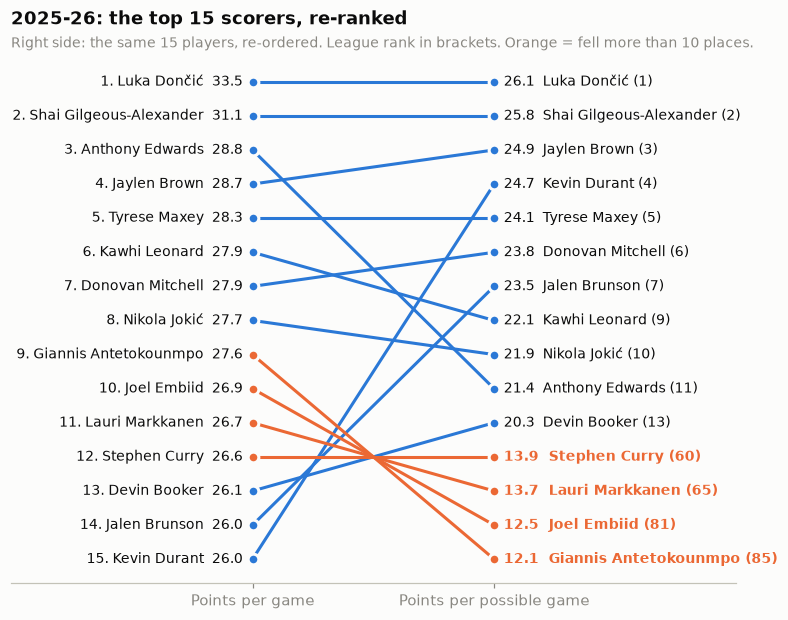

In [4]:
x = done[done.season == LATEST].nsmallest(15, "ppg_rank").copy()
x["left"] = range(1, 16)                                    # order by points per game
x["right"] = x.pppg.rank(ascending=False, method="first")   # same 15, ordered by points per possible game
fig, ax = plt.subplots(figsize=(8.5, 6.2))
FALL = 10  # a fall of more than 10 league places is highlighted
for _, r in x.iterrows():
    fell = r.pppg_rank - r.ppg_rank > FALL
    colour = plotting.SERIES[1] if fell else plotting.SERIES[0]
    ax.plot([0, 1], [r.left, r.right], color=colour, lw=2, marker="o", ms=7, mec=plotting.SURFACE, mew=2, zorder=3 if fell else 2)
    ax.text(-0.04, r.left, f"{int(r.ppg_rank)}. {r.player_name}  {r.ppg:.1f}", ha="right", va="center", fontsize=9)
    ax.text(1.04, r.right, f"{r.pppg:.1f}  {r.player_name} ({int(r.pppg_rank)})", ha="left", va="center", fontsize=9,
            color=plotting.SERIES[1] if fell else plotting.INK, fontweight="bold" if fell else "normal")
ax.invert_yaxis()
ax.set_yticks([])
ax.set_xticks([0, 1], ["Points per game", "Points per possible game"])
ax.set_xlim(-1.0, 2.0)
ax.grid(False); ax.spines["left"].set_visible(False)
ax.set_title(f"{LATEST}: the top 15 scorers, re-ranked", pad=22)
ax.text(0, 1.02, "Right side: the same 15 players, re-ordered. League rank in brackets. Orange = fell more than 10 places.",
        transform=ax.transAxes, color=plotting.MUTED, fontsize=9)
plotting.save(fig, f"2_rerank_{LATEST}");

In [5]:
show = x[["player_name", "gp", "possible_games", "ppg", "ppg_rank", "pppg", "pppg_rank", "Note"]].copy()
show.columns = ["Player", "Played", "Possible games", "PPG", "PPG rank", "PPPG", "PPPG rank", "Note"]
show[["PPG rank", "PPPG rank"]] = show[["PPG rank", "PPPG rank"]].astype(int)
table(show.reset_index(drop=True), f"{LATEST}: top 15 by points per game")

Player,Played,Possible games,PPG,PPG rank,PPPG,PPPG rank,Note
Luka Dončić,64,82,33.5,1,26.1,1,
Shai Gilgeous-Alexander,68,82,31.1,2,25.8,2,
Anthony Edwards,61,82,28.8,3,21.4,11,
Jaylen Brown,71,82,28.7,4,24.9,3,
Tyrese Maxey,70,82,28.3,5,24.1,5,
Kawhi Leonard,65,82,27.9,6,22.1,9,
Donovan Mitchell,70,82,27.9,7,23.8,6,
Nikola Jokić,65,82,27.7,8,21.9,10,
Giannis Antetokounmpo,36,82,27.6,9,12.1,85,
Joel Embiid,38,82,26.9,10,12.5,81,


## 4. The top 15 scorers in every season

**What you're looking at:** the same comparison for every complete season: the top 15 by points per game, and where each ranks by points per possible game.  
**Why it matters:** shows whether the pattern holds year after year, and which players fall again and again.

In [6]:
for season in data.COMPLETE_SEASONS:
    s = done[done.season == season].nsmallest(15, "ppg_rank")
    s = s[["player_name", "gp", "possible_games", "ppg", "pppg", "pppg_rank", "Note"]].copy()
    s.columns = ["Player", "Played", "Possible games", "PPG", "PPPG", "PPPG rank", "Note"]
    s["PPPG rank"] = s["PPPG rank"].astype(int)
    display(table(s.reset_index(drop=True), f"{season}: top 15 by points per game"))

Player,Played,Possible games,PPG,PPPG,PPPG rank,Note
Stephen Curry,63,72,32.0,28.0,1,
Bradley Beal,60,72,31.3,26.1,4,
Damian Lillard,67,72,28.8,26.8,2,
Joel Embiid,51,72,28.5,20.2,16,
Giannis Antetokounmpo,61,72,28.1,23.8,6,
Luka Dončić,66,72,27.7,25.4,5,
Zach LaVine,58,72,27.4,22.1,13,
Zion Williamson,61,72,27.0,22.9,10,
Kevin Durant,35,72,26.9,13.1,64,
Kyrie Irving,54,72,26.9,20.2,16,


Player,Played,Possible games,PPG,PPPG,PPPG rank,Note
Joel Embiid,68,82,30.6,25.4,3,
LeBron James,56,82,30.3,20.7,11,
Giannis Antetokounmpo,67,82,29.9,24.4,6,
Kevin Durant,55,82,29.9,20.0,12,
Luka Dončić,65,82,28.4,22.5,7,
Trae Young,76,82,28.4,26.3,1,
DeMar DeRozan,76,82,27.9,25.8,2,
Kyrie Irving,29,82,27.4,9.7,127,
Ja Morant,57,82,27.4,19.1,16,
Nikola Jokić,74,82,27.1,24.4,5,


Player,Played,Possible games,PPG,PPPG,PPPG rank,Note
Joel Embiid,66,82,33.1,26.6,2,
Luka Dončić,66,82,32.4,26.1,3,
Damian Lillard,58,82,32.2,22.8,11,
Shai Gilgeous-Alexander,68,82,31.4,26.0,4,
Giannis Antetokounmpo,63,82,31.1,23.9,5,
Jayson Tatum,74,82,30.1,27.1,1,
Stephen Curry,56,82,29.4,20.1,21,
Kevin Durant,47,80,29.1,17.1,40,
LeBron James,55,82,28.9,19.4,25,
Donovan Mitchell,68,82,28.3,23.4,8,


Player,Played,Possible games,PPG,PPPG,PPPG rank,Note
Joel Embiid,39,82,34.7,16.5,48,
Luka Dončić,70,82,33.9,28.9,1,
Giannis Antetokounmpo,73,82,30.4,27.1,3,
Shai Gilgeous-Alexander,75,82,30.1,27.5,2,
Jalen Brunson,77,82,28.7,27.0,4,
Kevin Durant,75,82,27.1,24.8,7,
Devin Booker,68,82,27.1,22.5,13,
Jayson Tatum,74,82,26.9,24.2,8,
Donovan Mitchell,55,82,26.6,17.8,33,
De'Aaron Fox,74,82,26.6,24.0,9,


Player,Played,Possible games,PPG,PPPG,PPPG rank,Note
Shai Gilgeous-Alexander,76,82,32.7,30.3,1,
Giannis Antetokounmpo,67,82,30.4,24.8,4,
Nikola Jokić,70,82,29.6,25.3,3,
Luka Dončić,50,84,28.2,16.8,36,
Anthony Edwards,79,82,27.6,26.5,2,
Jayson Tatum,72,82,26.8,23.6,5,
Kevin Durant,62,82,26.6,20.1,19,
Tyrese Maxey,52,82,26.3,16.7,37,
Cade Cunningham,70,82,26.1,22.3,9,
Jalen Brunson,65,82,26.0,20.6,17,


Player,Played,Possible games,PPG,PPPG,PPPG rank,Note
Luka Dončić,64,82,33.5,26.1,1,
Shai Gilgeous-Alexander,68,82,31.1,25.8,2,
Anthony Edwards,61,82,28.8,21.4,11,
Jaylen Brown,71,82,28.7,24.9,3,
Tyrese Maxey,70,82,28.3,24.1,5,
Kawhi Leonard,65,82,27.9,22.1,9,
Donovan Mitchell,70,82,27.9,23.8,6,
Nikola Jokić,65,82,27.7,21.9,10,
Giannis Antetokounmpo,36,82,27.6,12.1,85,
Joel Embiid,38,82,26.9,12.5,81,


## 5. The biggest falls

**What you're looking at:** across all six seasons, the top-15 scorers who fell furthest once missed games were counted.  
**Why it matters:** these are the seasons where a big scoring average hid the most missing games.

In [7]:
top15 = done[done.ppg_rank <= 15].copy()
top15["Places fallen"] = (top15.pppg_rank - top15.ppg_rank).astype(int)
falls = top15.nlargest(10, "Places fallen")[["season", "player_name", "gp", "possible_games", "ppg", "ppg_rank", "pppg", "pppg_rank", "Places fallen"]]
falls.columns = ["Season", "Player", "Played", "Possible games", "PPG", "PPG rank", "PPPG", "PPPG rank", "Places fallen"]
falls[["PPG rank", "PPPG rank"]] = falls[["PPG rank", "PPPG rank"]].astype(int)
table(falls.reset_index(drop=True), "Biggest falls among the top 15 scorers, 2020-21 to 2025-26")

Season,Player,Played,Possible games,PPG,PPG rank,PPPG,PPPG rank,Places fallen
2021-22,Kyrie Irving,29,82,27.4,8,9.7,127,119
2025-26,Giannis Antetokounmpo,36,82,27.6,9,12.1,85,76
2025-26,Joel Embiid,38,82,26.9,10,12.5,81,71
2020-21,Kevin Durant,35,72,26.9,9,13.1,64,55
2025-26,Lauri Markkanen,42,82,26.7,11,13.7,65,54
2025-26,Stephen Curry,43,82,26.6,12,13.9,60,48
2023-24,Joel Embiid,39,82,34.7,1,16.5,48,47
2024-25,LaMelo Ball,47,82,25.2,13,14.4,60,47
2024-25,Paolo Banchero,46,82,25.9,11,14.5,58,47
2024-25,Anthony Davis,51,80,24.7,15,15.8,50,35


## 6. Every player in one picture

**What you're looking at:** every player in 2025-26: points per game across, points per possible game up. A player who never missed a game sits on the diagonal line.  
**Why it matters:** the further below the line, the more games a player missed. High scorers far below the line are the ones whose averages hide their absences.

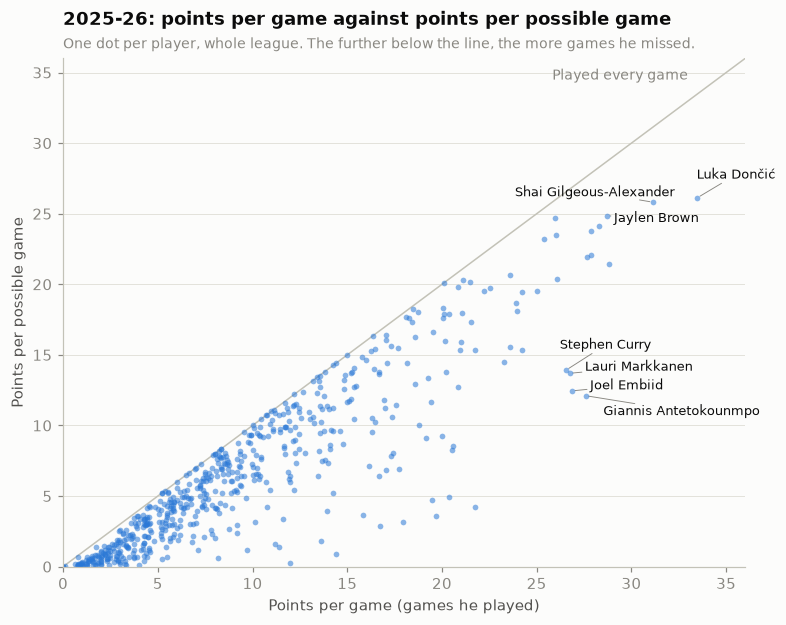

In [8]:
x = done[(done.season == LATEST) & (done.gp > 0)]
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 36], [0, 36], color=plotting.AXIS, lw=1, zorder=1)
ax.text(33, 34.5, "Played every game", color=plotting.MUTED, fontsize=9, ha="right")
ax.scatter(x.ppg, x.pppg, s=14, color=plotting.SERIES[0], alpha=0.55, linewidths=0, zorder=2)
label = pd.concat([x.nsmallest(3, "pppg_rank"), x[x.ppg_rank <= 15].nlargest(4, "pppg_rank")]).drop_duplicates("player_id")
texts = [ax.text(r.ppg, r.pppg, r.player_name, fontsize=8.5, color=plotting.INK) for _, r in label.iterrows()]
adjust_text(texts, x=label.ppg.values, y=label.pppg.values, ax=ax,
            arrowprops=dict(arrowstyle="-", color=plotting.MUTED, lw=0.6))
ax.set_xlim(0, 36); ax.set_ylim(0, 36)
ax.set_xlabel("Points per game (games he played)")
ax.set_ylabel("Points per possible game")
ax.set_title(f"{LATEST}: points per game against points per possible game", pad=22)
ax.text(0, 1.02, "One dot per player, whole league. The further below the line, the more games he missed.",
        transform=ax.transAxes, color=plotting.MUTED, fontsize=9)
plotting.save(fig, f"2_scatter_{LATEST}");

## 7. Joel Embiid, the case that started it

**What you're looking at:** Embiid's points per game and points per possible game in each complete season.  
**Why it matters:** the gap between the two lines is what his absences cost: in his three scoring-title seasons the gap grew as his games played fell.

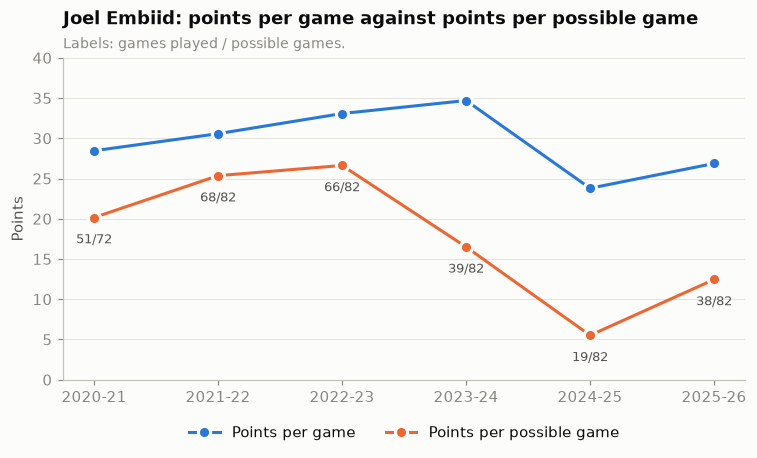

In [9]:
e = done[done.player_name == "Joel Embiid"].set_index("season")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(e.index, e.ppg, color=plotting.SERIES[0], lw=2, marker="o", ms=8, mec=plotting.SURFACE, mew=2, label="Points per game")
ax.plot(e.index, e.pppg, color=plotting.SERIES[1], lw=2, marker="o", ms=8, mec=plotting.SURFACE, mew=2, label="Points per possible game")
for s, r in e.iterrows():
    ax.text(s, r.pppg - 3.2, f"{r.gp}/{r.possible_games}", ha="center", fontsize=8.5, color=plotting.INK_2)
ax.set_ylim(0, 40)
ax.set_ylabel("Points")
ax.set_title("Joel Embiid: points per game against points per possible game", pad=22)
ax.text(0, 1.03, "Labels: games played / possible games.", transform=ax.transAxes, color=plotting.MUTED, fontsize=9)
ax.legend(loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.1))
plotting.save(fig, "2_embiid");

In [10]:
t = e[["gp", "possible_games", "ppg", "ppg_rank", "pppg", "pppg_rank"]].copy()
t.columns = ["Played", "Possible games", "PPG", "PPG rank", "PPPG", "PPPG rank"]
t[["PPG rank", "PPPG rank"]] = t[["PPG rank", "PPPG rank"]].astype(int)
table(t.rename_axis("Season"), "Joel Embiid, season by season")

,Played,Possible games,PPG,PPG rank,PPPG,PPPG rank
Season,,,,,,
2020-21,51,72,28.5,4,20.2,16
2021-22,68,82,30.6,1,25.4,3
2022-23,66,82,33.1,1,26.6,2
2023-24,39,82,34.7,1,16.5,48
2024-25,19,82,23.8,27,5.5,258
2025-26,38,82,26.9,10,12.5,81


## 8. Per minute: PPM and PPPM

**What you're looking at:** the top 10 in 2025-26 by points per minute played, next to their rank by points per possible minute.  
**Why it matters:** points per minute is topped by players who played only a few minutes, because one hot night is enough. Points per possible minute (48 minutes for every possible game) puts the same players in the same order as points per possible game, so it adds nothing new: it is shown for completeness.

In [11]:
x = done[done.season == LATEST].nsmallest(10, "ppm_rank")
t = x[["player_name", "gp", "min", "ppm", "pppm", "pppm_rank", "Note"]].copy()
t.columns = ["Player", "Played", "Minutes", "PPM", "PPPM", "PPPM rank", "Note"]
t["PPPM rank"] = t["PPPM rank"].astype(int)
table(t.reset_index(drop=True), f"{LATEST}: top 10 by points per minute", precision=2)

Player,Played,Minutes,PPM,PPPM,PPPM rank,Note
Tristen Newton,1,12,1.00,0.00,553,Two-way contract
Giannis Antetokounmpo,36,"1,039",0.96,0.25,85,
Alex Antetokounmpo,6,20,0.95,0.05,418,Two-way contract
Shai Gilgeous-Alexander,68,"2,261",0.94,0.54,2,
Luka Dončić,64,"2,293",0.93,0.54,1,
Kawhi Leonard,65,"2,087",0.87,0.46,9,
Ty Jerome,15,341,0.87,0.07,360,
Stephen Curry,43,"1,331",0.86,0.29,60,
Victor Wembanyama,64,"1,867",0.86,0.41,19,
Joel Embiid,38,"1,197",0.85,0.26,81,


## 9. This season so far (2026-27)

**What you're looking at:** the top 10 by points per possible game in the season being played now, with their points per game.  
**Why it matters:** an early look only: about 17 games in, one injury can move a player a long way.

In [12]:
now = ps[ps.season == data.IN_PROGRESS].nsmallest(10, "pppg_rank")
t = now[["player_name", "gp", "possible_games", "ppg", "ppg_rank", "pppg", "Note"]].copy()
t.columns = ["Player", "Played", "Possible games", "PPG", "PPG rank", "PPPG", "Note"]
t["PPG rank"] = t["PPG rank"].astype(int)
table(t.reset_index(drop=True), f"{data.IN_PROGRESS} so far: top 10 by points per possible game")

Player,Played,Possible games,PPG,PPG rank,PPPG,Note
Luka Dončić,15,17,37.2,1,32.8,
Victor Wembanyama,17,17,29.9,4,29.9,
Shai Gilgeous-Alexander,17,18,30.4,3,28.7,
Jalen Brunson,17,17,26.5,7,26.5,
Giannis Antetokounmpo,15,16,28.2,5,26.4,
Jamal Murray,15,15,26.2,9,26.2,
Darius Acuff Jr.,16,16,25.4,10,25.4,
Nikola Jokić,15,15,25.1,13,25.1,
Franz Wagner,16,16,24.5,15,24.5,
Tyrese Maxey,17,18,25.1,12,23.7,


---
Every rule used here is listed, with its reason, in `docs/DECISIONS.md`.